# Traductor Español-Inglés / Inglés-Español mediante Redes Neuronales Recurrentes

## Integrantes
- Vicente Alonso Fuentes Lagos
- Marlon Gabriel Abreu Galviz

## Objetivo
Desarrollar un modelo de traducción automática capaz de traducir oraciones entre Español e Inglés utilizando redes neuronales recurrentes.

Se compararán arquitecturas RNN y LSTM, utilizando modelos construidos y entrenados con TensorFlow/Keras, sin utilizar modelos de traducción preentrenados.

# 1. Primeros pasos

* **Librerías y semillas**

In [2]:
# Librerías
import re
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files

from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

from tensorflow import keras

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Embedding
from tensorflow.keras.layers import SimpleRNN
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dense

from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Semillas
np.random.seed(42)
tf.random.set_seed(42)
keras.utils.set_random_seed(42)

* **Carga del dataset**

El dataset contiene una oración en inglés, su traducción al español y la fuente correspondiente.

In [3]:
# Subir spa.txt
archivos = files.upload()

nombre_archivo = list(
    archivos.keys()
)[0]

ruta_txt = "/content/" + nombre_archivo

# Cargar dataset
df_original = pd.read_csv(
    ruta_txt,
    sep="\t",
    header=None,
    names=[
        "Inglés",
        "Español",
        "Fuente"
    ],
    quoting=csv.QUOTE_NONE,
    on_bad_lines="skip"
)

print(
    "Cantidad original de pares:",
    len(df_original)
)

df_original.head()

Saving spa.txt to spa.txt
Cantidad original de pares: 144215


,Inglés,Español,Fuente
0,Go.,Ve.,CC-BY 2.0 (France) Attribution: tatoeba.org #2...
1,Go.,Vete.,CC-BY 2.0 (France) Attribution: tatoeba.org #2...
2,Go.,Vaya.,CC-BY 2.0 (France) Attribution: tatoeba.org #2...
3,Go.,Váyase.,CC-BY 2.0 (France) Attribution: tatoeba.org #2...
4,Go.,Id.,CC-BY 2.0 (France) Attribution: tatoeba.org #2...


# 2. Exploración del dataset

* **Validación del largo de las oraciones**

Las oraciones utilizadas deben contener entre 3 y 20 palabras y tener un máximo de 100 caracteres.

La condición se verifica tanto para las oraciones en Español como para sus traducciones en Inglés.

In [4]:
def contar_palabras(texto):

    return len(
        str(texto).split()
    )


def validar_oracion(texto):

    cantidad_palabras = contar_palabras(
        texto
    )

    cantidad_caracteres = len(
        str(texto)
    )

    return (
        3 <= cantidad_palabras <= 20
        and cantidad_caracteres <= 100
    )


# Eliminar datos nulos
df = df_original.dropna(
    subset=[
        "Español",
        "Inglés"
    ]
).copy()


# Eliminar pares duplicados
df = df.drop_duplicates(
    subset=[
        "Español",
        "Inglés"
    ]
)


# Aplicar restricciones
df = df[
    df["Español"].apply(
        validar_oracion
    )
    &
    df["Inglés"].apply(
        validar_oracion
    )
].copy()


print(
    "Pares que cumplen las condiciones:",
    len(df)
)

Pares que cumplen las condiciones: 135311


* **Selección de datos**

Luego de aplicar las restricciones de largo y eliminar registros inválidos o duplicados, se selecciona una muestra aleatoria de 10.000 pares de oraciones para reducir los tiempos de entrenamiento.

Se utiliza una semilla fija para mantener la reproducibilidad de los resultados.

In [5]:
CANTIDAD_DATOS = 10000

# Seleccionar una muestra aleatoria
df = df.sample(
    n=min(
        CANTIDAD_DATOS,
        len(df)
    ),
    random_state=42
).reset_index(
    drop=True
)

print(
    "Cantidad de pares utilizados:",
    len(df)
)

df[
    [
        "Español",
        "Inglés"
    ]
].head(10)

Cantidad de pares utilizados: 10000


,Español,Inglés
0,Serás una madre maravillosa.,You'll be a wonderful mother.
1,Salvaron a todos.,Everyone was saved.
2,Quiero que trabajes más.,I want you to work harder.
3,Hay una fina línea entre lo aceptable y lo ina...,There's a fine line between what's acceptable ...
4,Él no quería decepcionar a su madre.,He didn't want to disappoint his mother.
5,Hoy es el gran día.,Today's the big day.
6,Yo la quiero y ella me quiere.,I love her and she loves me.
7,Tom siempre bebe por lo menos tres tazas de ca...,Tom always drinks at least three cups of coffe...
8,Se merece el castigo.,He deserves the punishment.
9,A Tom no le gusta quedarse en casa.,Tom doesn't like to stay at home.


* **Cantidad de palabras por idioma**

In [6]:
df["Palabras Español"] = df[
    "Español"
].apply(
    contar_palabras
)

df["Palabras Inglés"] = df[
    "Inglés"
].apply(
    contar_palabras
)


tabla_longitudes = pd.DataFrame({

    "Idioma": [
        "Español",
        "Inglés"
    ],

    "Mínimo": [
        df["Palabras Español"].min(),
        df["Palabras Inglés"].min()
    ],

    "Máximo": [
        df["Palabras Español"].max(),
        df["Palabras Inglés"].max()
    ],

    "Promedio": [
        round(
            df["Palabras Español"].mean(),
            2
        ),
        round(
            df["Palabras Inglés"].mean(),
            2
        )
    ]

})

tabla_longitudes

,Idioma,Mínimo,Máximo,Promedio
0,Español,3,20,6.14
1,Inglés,3,20,6.37


* **Distribución del largo de las oraciones**

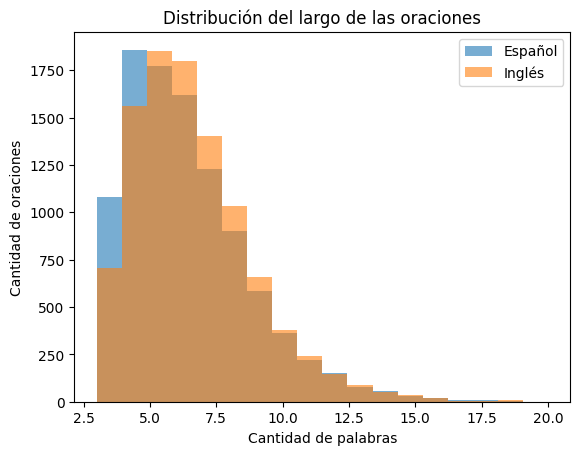

In [7]:
plt.hist(
    df["Palabras Español"],
    bins=18,
    alpha=0.6,
    label="Español"
)

plt.hist(
    df["Palabras Inglés"],
    bins=18,
    alpha=0.6,
    label="Inglés"
)

plt.xlabel(
    "Cantidad de palabras"
)

plt.ylabel(
    "Cantidad de oraciones"
)

plt.title(
    "Distribución del largo de las oraciones"
)

plt.legend()

plt.show()

# 3. Preparar los datos

* **Limpieza del texto**

Las oraciones se convierten a minúsculas y se eliminan signos de puntuación.

Esto permite trabajar con una representación más uniforme del vocabulario antes de convertir las palabras a valores numéricos.



In [8]:
def limpiar_texto(texto):

    texto = str(
        texto
    ).lower().strip()

    texto = re.sub(
        r"[^a-záéíóúüñ\s]",
        "",
        texto
    )

    texto = re.sub(
        r"\s+",
        " ",
        texto
    )

    return texto


df["Español limpio"] = df[
    "Español"
].apply(
    limpiar_texto
)

df["Inglés limpio"] = df[
    "Inglés"
].apply(
    limpiar_texto
)


df[
    [
        "Español",
        "Español limpio",
        "Inglés",
        "Inglés limpio"
    ]
].head()

,Español,Español limpio,Inglés,Inglés limpio
0,Serás una madre maravillosa.,serás una madre maravillosa,You'll be a wonderful mother.,youll be a wonderful mother
1,Salvaron a todos.,salvaron a todos,Everyone was saved.,everyone was saved
2,Quiero que trabajes más.,quiero que trabajes más,I want you to work harder.,i want you to work harder
3,Hay una fina línea entre lo aceptable y lo ina...,hay una fina línea entre lo aceptable y lo ina...,There's a fine line between what's acceptable ...,theres a fine line between whats acceptable an...
4,Él no quería decepcionar a su madre.,él no quería decepcionar a su madre,He didn't want to disappoint his mother.,he didnt want to disappoint his mother


* **Separar entrenamiento, validación y prueba**

Los datos se separan aproximadamente en:

- 70% para entrenamiento.
- 15% para validación.
- 15% para prueba.

El conjunto de entrenamiento se utiliza para que los modelos aprendan.

Validación se utiliza para comparar arquitecturas e hiperparámetros.

Prueba queda reservada para evaluar la configuración final.

In [9]:
df_train, df_temporal = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)


df_val, df_test = train_test_split(
    df_temporal,
    test_size=0.50,
    random_state=42
)


df_train = df_train.reset_index(
    drop=True
)

df_val = df_val.reset_index(
    drop=True
)

df_test = df_test.reset_index(
    drop=True
)


print(
    "Entrenamiento:",
    len(df_train)
)

print(
    "Validación:",
    len(df_val)
)

print(
    "Prueba:",
    len(df_test)
)

Entrenamiento: 7000
Validación: 1500
Prueba: 1500


* **Tokenización, secuencias y Padding**

Las redes neuronales trabajan con valores numéricos, por lo que cada palabra debe convertirse en un identificador.

El Tokenizer crea un vocabulario y asigna un número a cada palabra.

Posteriormente se utiliza Padding para que todas las secuencias tengan el mismo largo.

En las oraciones de destino se agregan las marcas `startseq` y `endseq`, que permiten indicar el inicio y el final de una traducción.

In [10]:
MAX_PALABRAS = 20


def preparar_direccion(
    df_train,
    df_val,
    df_test,
    columna_origen,
    columna_destino
):

    # Oraciones de entrada
    origen_train = df_train[
        columna_origen
    ].tolist()

    origen_val = df_val[
        columna_origen
    ].tolist()

    origen_test = df_test[
        columna_origen
    ].tolist()


    # Oraciones de salida
    destino_train = [
        "startseq "
        + texto
        + " endseq"

        for texto in df_train[
            columna_destino
        ]
    ]


    destino_val = [
        "startseq "
        + texto
        + " endseq"

        for texto in df_val[
            columna_destino
        ]
    ]


    destino_test = [
        "startseq "
        + texto
        + " endseq"

        for texto in df_test[
            columna_destino
        ]
    ]


    # Tokenizers
    tokenizer_origen = Tokenizer(
        filters="",
        oov_token="oov"
    )

    tokenizer_destino = Tokenizer(
        filters="",
        oov_token="oov"
    )


    # Crear vocabularios solo con entrenamiento
    tokenizer_origen.fit_on_texts(
        origen_train
    )

    tokenizer_destino.fit_on_texts(
        destino_train
    )


    max_origen = MAX_PALABRAS

    max_destino = (
        MAX_PALABRAS + 2
    )


    def convertir(
        origen,
        destino
    ):

        # Convertir palabras a números
        x = tokenizer_origen.texts_to_sequences(
            origen
        )

        y = tokenizer_destino.texts_to_sequences(
            destino
        )


        # Padding
        x = pad_sequences(
            x,
            maxlen=max_origen,
            padding="post",
            truncating="post"
        )


        y = pad_sequences(
            y,
            maxlen=max_destino,
            padding="post",
            truncating="post"
        )


        # Entrada del decoder
        decoder_input = y[
            :,
            :-1
        ]


        # Palabra que debe predecir
        decoder_target = y[
            :,
            1:
        ]


        # Ignorar Padding durante entrenamiento
        pesos = (
            decoder_target != 0
        ).astype(
            "float32"
        )


        return (
            x,
            decoder_input,
            decoder_target,
            pesos
        )


    return {

        "tokenizer_origen":
            tokenizer_origen,

        "tokenizer_destino":
            tokenizer_destino,

        "max_origen":
            max_origen,

        "max_destino":
            max_destino,

        "vocab_origen":
            len(
                tokenizer_origen.word_index
            ) + 1,

        "vocab_destino":
            len(
                tokenizer_destino.word_index
            ) + 1,

        "train":
            convertir(
                origen_train,
                destino_train
            ),

        "val":
            convertir(
                origen_val,
                destino_val
            ),

        "test":
            convertir(
                origen_test,
                destino_test
            )
    }

* **Preparar traducción Español → Inglés**

In [11]:
datos_es_en = preparar_direccion(
    df_train,
    df_val,
    df_test,
    "Español limpio",
    "Inglés limpio"
)


print(
    "Vocabulario Español:",
    datos_es_en[
        "vocab_origen"
    ]
)

print(
    "Vocabulario Inglés:",
    datos_es_en[
        "vocab_destino"
    ]
)

print(
    "Largo máximo de entrada:",
    datos_es_en[
        "max_origen"
    ]
)

print(
    "Largo máximo de salida:",
    datos_es_en[
        "max_destino"
    ]
)

Vocabulario Español: 6308
Vocabulario Inglés: 4179
Largo máximo de entrada: 20
Largo máximo de salida: 22


* **Preparar traducción Inglés → Español**

In [12]:
datos_en_es = preparar_direccion(
    df_train,
    df_val,
    df_test,
    "Inglés limpio",
    "Español limpio"
)


print(
    "Vocabulario Inglés:",
    datos_en_es[
        "vocab_origen"
    ]
)

print(
    "Vocabulario Español:",
    datos_en_es[
        "vocab_destino"
    ]
)

Vocabulario Inglés: 4177
Vocabulario Español: 6310


# 4. Creación de los modelos recurrentes

* **Modelo RNN base**

Una RNN procesa una secuencia palabra por palabra y mantiene un estado oculto que contiene información de los elementos anteriores.

Para este problema se utiliza una arquitectura Encoder-Decoder.

El Encoder procesa la oración de entrada y genera un estado interno.

El Decoder utiliza ese estado para producir la oración traducida.

La arquitectura es:

Entrada → Embedding → Encoder RNN → Estado oculto → Decoder RNN → Dense → Softmax

In [13]:
def crear_modelo_rnn(
    vocab_origen,
    vocab_destino,
    embedding_dim=64,
    unidades=128,
    learning_rate=0.001
):

    # Encoder
    entrada_encoder = Input(
        shape=(None,)
    )


    capa_embedding_encoder = Embedding(
        vocab_origen,
        embedding_dim,
        mask_zero=True
    )


    embedding_encoder = (
        capa_embedding_encoder(
            entrada_encoder
        )
    )


    capa_encoder = SimpleRNN(
        unidades,
        return_state=True
    )


    _, estado_encoder = capa_encoder(
        embedding_encoder
    )


    # Decoder
    entrada_decoder = Input(
        shape=(None,)
    )


    capa_embedding_decoder = Embedding(
        vocab_destino,
        embedding_dim,
        mask_zero=True
    )


    embedding_decoder = (
        capa_embedding_decoder(
            entrada_decoder
        )
    )


    capa_decoder = SimpleRNN(
        unidades,
        return_sequences=True,
        return_state=True
    )


    salida_decoder, _ = capa_decoder(

        embedding_decoder,

        initial_state=
        estado_encoder
    )


    capa_salida = Dense(
        vocab_destino,
        activation="softmax"
    )


    salida = capa_salida(
        salida_decoder
    )


    # Modelo de entrenamiento
    modelo = Model(
        [
            entrada_encoder,
            entrada_decoder
        ],
        salida
    )


    modelo.compile(

        optimizer=Adam(
            learning_rate=
            learning_rate
        ),

        loss=
        "sparse_categorical_crossentropy",

        weighted_metrics=[
            keras.metrics
            .SparseCategoricalAccuracy(
                name="accuracy"
            )
        ]
    )


    # Encoder para realizar traducciones
    modelo_encoder = Model(
        entrada_encoder,
        estado_encoder
    )


    # Decoder para realizar traducciones
    token_input = Input(
        shape=(1,)
    )

    estado_input = Input(
        shape=(unidades,)
    )


    token_embedding = (
        capa_embedding_decoder(
            token_input
        )
    )


    token_output, estado_output = (
        capa_decoder(

            token_embedding,

            initial_state=
            estado_input
        )
    )


    token_probabilidad = capa_salida(
        token_output
    )


    modelo_decoder = Model(

        [
            token_input,
            estado_input
        ],

        [
            token_probabilidad,
            estado_output
        ]
    )


    return (
        modelo,
        modelo_encoder,
        modelo_decoder
    )

* **Modelo LSTM base**

La LSTM también procesa secuencias, pero incorpora un estado de memoria que permite conservar información durante más pasos.

El Encoder LSTM genera dos estados: el estado oculto `h` y el estado de memoria `c`.

Estos estados son enviados al Decoder para comenzar a generar la traducción.

La arquitectura es:

Entrada → Embedding → Encoder LSTM → Estados h y c → Decoder LSTM → Dense → Softmax

In [14]:
def crear_modelo_lstm(
    vocab_origen,
    vocab_destino,
    embedding_dim=64,
    unidades=128,
    learning_rate=0.001
):

    # Encoder
    entrada_encoder = Input(
        shape=(None,)
    )


    capa_embedding_encoder = Embedding(
        vocab_origen,
        embedding_dim,
        mask_zero=True
    )


    embedding_encoder = (
        capa_embedding_encoder(
            entrada_encoder
        )
    )


    capa_encoder = LSTM(
        unidades,
        return_state=True
    )


    _, estado_h, estado_c = capa_encoder(
        embedding_encoder
    )


    # Decoder
    entrada_decoder = Input(
        shape=(None,)
    )


    capa_embedding_decoder = Embedding(
        vocab_destino,
        embedding_dim,
        mask_zero=True
    )


    embedding_decoder = (
        capa_embedding_decoder(
            entrada_decoder
        )
    )


    capa_decoder = LSTM(
        unidades,
        return_sequences=True,
        return_state=True
    )


    salida_decoder, _, _ = capa_decoder(

        embedding_decoder,

        initial_state=[
            estado_h,
            estado_c
        ]
    )


    capa_salida = Dense(
        vocab_destino,
        activation="softmax"
    )


    salida = capa_salida(
        salida_decoder
    )


    # Modelo de entrenamiento
    modelo = Model(
        [
            entrada_encoder,
            entrada_decoder
        ],
        salida
    )


    modelo.compile(

        optimizer=Adam(
            learning_rate=
            learning_rate
        ),

        loss=
        "sparse_categorical_crossentropy",

        weighted_metrics=[
            keras.metrics
            .SparseCategoricalAccuracy(
                name="accuracy"
            )
        ]
    )


    # Encoder para traducción
    modelo_encoder = Model(

        entrada_encoder,

        [
            estado_h,
            estado_c
        ]
    )


    # Decoder para traducción
    token_input = Input(
        shape=(1,)
    )

    h_input = Input(
        shape=(unidades,)
    )

    c_input = Input(
        shape=(unidades,)
    )


    token_embedding = (
        capa_embedding_decoder(
            token_input
        )
    )


    token_output, h_output, c_output = (
        capa_decoder(

            token_embedding,

            initial_state=[
                h_input,
                c_input
            ]
        )
    )


    token_probabilidad = capa_salida(
        token_output
    )


    modelo_decoder = Model(

        [
            token_input,
            h_input,
            c_input
        ],

        [
            token_probabilidad,
            h_output,
            c_output
        ]
    )


    return (
        modelo,
        modelo_encoder,
        modelo_decoder
    )

* **Función para seleccionar arquitectura**

Esta función permite crear una RNN o una LSTM utilizando los mismos parámetros, facilitando posteriormente la comparación de configuraciones.

In [15]:
def crear_modelo_recurrente(
    arquitectura,
    vocab_origen,
    vocab_destino,
    embedding_dim=64,
    unidades=128,
    learning_rate=0.001
):

    if arquitectura == "RNN":

        return crear_modelo_rnn(
            vocab_origen,
            vocab_destino,
            embedding_dim,
            unidades,
            learning_rate
        )


    return crear_modelo_lstm(
        vocab_origen,
        vocab_destino,
        embedding_dim,
        unidades,
        learning_rate
    )

# 5. Entrenamiento y comparación RNN vs LSTM

Para realizar la comparación inicial ambos modelos utilizarán la misma configuración:

- 5 épocas.
- Batch Size de 32.
- Learning Rate de 0,001.
- Embedding de 64 dimensiones.
- 128 unidades recurrentes.

De esta forma la principal diferencia durante la comparación será la arquitectura utilizada.

In [16]:
x_train, dec_train, y_train, w_train = datos_es_en["train"]

x_val, dec_val, y_val, w_val = datos_es_en["val"]

EPOCAS_BASE = 5
BATCH_BASE = 32
LR_BASE = 0.001

* **Entrenar modelo RNN**

In [17]:
keras.utils.set_random_seed(
    42
)


modelo_rnn, _, _ = crear_modelo_rnn(

    datos_es_en[
        "vocab_origen"
    ],

    datos_es_en[
        "vocab_destino"
    ],

    embedding_dim=64,

    unidades=128,

    learning_rate=
    LR_BASE
)


history_rnn = modelo_rnn.fit(

    [
        x_train,
        dec_train
    ],

    y_train,

    sample_weight=
    w_train,

    validation_data=(

        [
            x_val,
            dec_val
        ],

        y_val,

        w_val
    ),

    epochs=
    EPOCAS_BASE,

    batch_size=
    BATCH_BASE,

    verbose=1
)

Epoch 1/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 72s 317ms/step - accuracy: 0.1609 - loss: 5.2048 - val_accuracy: 0.1838 - val_loss: 4.7804
Epoch 2/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 79s 304ms/step - accuracy: 0.1980 - loss: 4.5335 - val_accuracy: 0.2133 - val_loss: 4.4948
Epoch 3/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 83s 308ms/step - accuracy: 0.2293 - loss: 4.2262 - val_accuracy: 0.2409 - val_loss: 4.3066
Epoch 4/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 73s 332ms/step - accuracy: 0.2506 - loss: 3.9900 - val_accuracy: 0.2520 - val_loss: 4.1987
Epoch 5/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 67s 307ms/step - accuracy: 0.2621 - loss: 3.8298 - val_accuracy: 0.2560 - val_loss: 4.1489


* **Entrenar modelo LSTM**

In [18]:
keras.utils.set_random_seed(
    42
)


modelo_lstm, _, _ = crear_modelo_lstm(

    datos_es_en[
        "vocab_origen"
    ],

    datos_es_en[
        "vocab_destino"
    ],

    embedding_dim=64,

    unidades=128,

    learning_rate=
    LR_BASE
)


history_lstm = modelo_lstm.fit(

    [
        x_train,
        dec_train
    ],

    y_train,

    sample_weight=
    w_train,

    validation_data=(

        [
            x_val,
            dec_val
        ],

        y_val,

        w_val
    ),

    epochs=
    EPOCAS_BASE,

    batch_size=
    BATCH_BASE,

    verbose=1
)

Epoch 1/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 81s 354ms/step - accuracy: 0.1605 - loss: 5.2225 - val_accuracy: 0.1767 - val_loss: 4.7603
Epoch 2/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 76s 348ms/step - accuracy: 0.1888 - loss: 4.6004 - val_accuracy: 0.1973 - val_loss: 4.6465
Epoch 3/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 76s 347ms/step - accuracy: 0.2010 - loss: 4.4303 - val_accuracy: 0.2060 - val_loss: 4.5512
Epoch 4/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 81s 342ms/step - accuracy: 0.2137 - loss: 4.2751 - val_accuracy: 0.2164 - val_loss: 4.4594
Epoch 5/5
219/219 ━━━━━━━━━━━━━━━━━━━━ 84s 349ms/step - accuracy: 0.2389 - loss: 4.0991 - val_accuracy: 0.2441 - val_loss: 4.3455


* **Accuracy durante el entrenamiento**

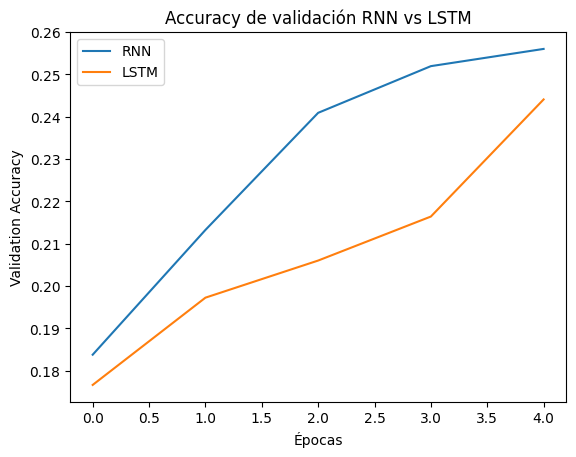

In [19]:
plt.plot(
    history_rnn.history[
        "val_accuracy"
    ],
    label="RNN"
)

plt.plot(
    history_lstm.history[
        "val_accuracy"
    ],
    label="LSTM"
)

plt.xlabel(
    "Épocas"
)

plt.ylabel(
    "Validation Accuracy"
)

plt.title(
    "Accuracy de validación RNN vs LSTM"
)

plt.legend()

plt.show()

* **Pérdida durante el entrenamiento**

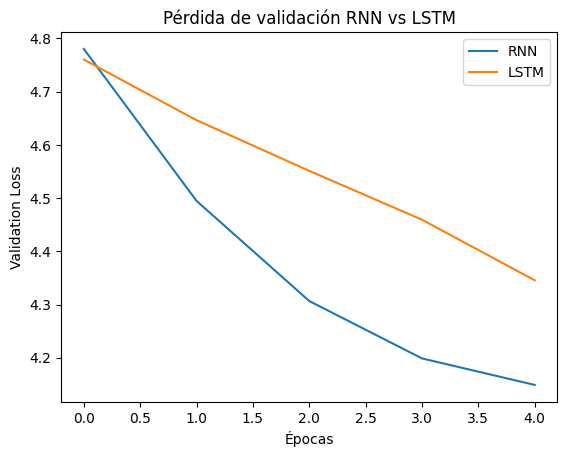

In [20]:
plt.plot(
    history_rnn.history[
        "val_loss"
    ],
    label="RNN"
)

plt.plot(
    history_lstm.history[
        "val_loss"
    ],
    label="LSTM"
)

plt.xlabel(
    "Épocas"
)

plt.ylabel(
    "Validation Loss"
)

plt.title(
    "Pérdida de validación RNN vs LSTM"
)

plt.legend()

plt.show()

# 6. Evaluación de los modelos



* **Métricas**

Para comparar los modelos se utilizarán Accuracy, Precision, Recall y F1-Score.

Las métricas se calculan a nivel de tokens, ignorando las posiciones agregadas por el Padding y utilizando las entradas correctas del Decoder.

- Accuracy indica la proporción de tokens predichos correctamente.
- Precision indica la proporción de predicciones correctas para cada clase.
- Recall indica la proporción de tokens reales identificados correctamente.
- F1-Score representa un equilibrio entre Precision y Recall.

Precision, Recall y F1-Score se calculan utilizando un promedio ponderado.

In [21]:
def evaluar_modelo(
    modelo,
    datos,
    batch_size=64
):

    x_encoder, x_decoder, y_real, pesos = datos


    resultado = modelo.evaluate(
        [
            x_encoder,
            x_decoder
        ],
        y_real,
        sample_weight=pesos,
        batch_size=batch_size,
        verbose=0,
        return_dict=True
    )


    reales_total = []
    predichos_total = []


    for inicio in range(
        0,
        len(x_encoder),
        batch_size
    ):

        fin = inicio + batch_size


        probabilidades = modelo(
            [
                x_encoder[inicio:fin],
                x_decoder[inicio:fin]
            ],
            training=False
        )


        y_pred = tf.argmax(
            probabilidades,
            axis=-1
        ).numpy()


        y_batch = y_real[
            inicio:fin
        ]


        mascara = (
            y_batch != 0
        )


        reales_total.append(
            y_batch[
                mascara
            ]
        )

        predichos_total.append(
            y_pred[
                mascara
            ]
        )


    reales = np.concatenate(
        reales_total
    )

    predichos = np.concatenate(
        predichos_total
    )


    return {

        "Loss":
            resultado["loss"],

        "Accuracy":
            accuracy_score(
                reales,
                predichos
            ),

        "Precision":
            precision_score(
                reales,
                predichos,
                average="weighted",
                zero_division=0
            ),

        "Recall":
            recall_score(
                reales,
                predichos,
                average="weighted",
                zero_division=0
            ),

        "F1-Score":
            f1_score(
                reales,
                predichos,
                average="weighted",
                zero_division=0
            )
    }

* **Comparación RNN vs LSTM**

In [22]:
metricas_rnn = evaluar_modelo(
    modelo_rnn,
    datos_es_en["val"]
)


metricas_lstm = evaluar_modelo(
    modelo_lstm,
    datos_es_en["val"]
)


tabla_modelos = pd.DataFrame([

    {
        "Modelo":
            "RNN",

        **metricas_rnn
    },

    {
        "Modelo":
            "LSTM",

        **metricas_lstm
    }

])


tabla_modelos

,Modelo,Loss,Accuracy,Precision,Recall,F1-Score
0,RNN,4.150555,0.256035,0.164461,0.256035,0.180626
1,LSTM,4.347106,0.244101,0.123905,0.244101,0.157969


### Interpretación RNN vs LSTM

El modelo RNN obtuvo mejores resultados que LSTM, alcanzando un Accuracy de 0,2560 y un F1-Score de 0,1806.

También presentó una menor pérdida de validación.

Por esta razón se selecciona la arquitectura RNN para los siguientes experimentos de hiperparámetros.

* **Selección de arquitectura**

Para seleccionar la arquitectura se priorizará el F1-Score de validación.

En caso de resultados similares también se considerarán Accuracy y Loss.

De esta manera la selección entre RNN y LSTM queda respaldada por los resultados obtenidos y no solamente por las características teóricas de cada arquitectura.

In [23]:
mejor_modelo = tabla_modelos.sort_values(

    by=[
        "F1-Score",
        "Accuracy",
        "Loss"
    ],

    ascending=[
        False,
        False,
        True
    ]

).iloc[0]


arquitectura_seleccionada = (
    mejor_modelo[
        "Modelo"
    ]
)


print(
    "Arquitectura seleccionada:",
    arquitectura_seleccionada
)

Arquitectura seleccionada: RNN


# 7. Experimentos y ajuste de hiperparámetros

* **Función para realizar experimentos**

Se mantiene la arquitectura seleccionada y se modifica un hiperparámetro a la vez.

Para reducir los tiempos de entrenamiento se utiliza una muestra de 3.000 pares de entrenamiento y 750 pares de validación.

Todos los experimentos utilizan las mismas muestras para mantener condiciones comparables.ecto sobre el rendimiento del modelo.

In [24]:
CANTIDAD_TRAIN_EXP = 3000
CANTIDAD_VAL_EXP = 750

x_train_exp = x_train[:CANTIDAD_TRAIN_EXP]
dec_train_exp = dec_train[:CANTIDAD_TRAIN_EXP]
y_train_exp = y_train[:CANTIDAD_TRAIN_EXP]
w_train_exp = w_train[:CANTIDAD_TRAIN_EXP]

datos_val_exp = (
    x_val[:CANTIDAD_VAL_EXP],
    dec_val[:CANTIDAD_VAL_EXP],
    y_val[:CANTIDAD_VAL_EXP],
    w_val[:CANTIDAD_VAL_EXP]
)


def probar_configuracion(
    epocas,
    batch,
    learning_rate
):

    keras.backend.clear_session()
    keras.utils.set_random_seed(42)

    modelo, _, _ = crear_modelo_recurrente(
        arquitectura_seleccionada,
        datos_es_en["vocab_origen"],
        datos_es_en["vocab_destino"],
        embedding_dim=64,
        unidades=128,
        learning_rate=learning_rate
    )

    modelo.fit(
        [x_train_exp, dec_train_exp],
        y_train_exp,
        sample_weight=w_train_exp,
        epochs=epocas,
        batch_size=batch,
        verbose=1
    )

    return evaluar_modelo(
        modelo,
        datos_val_exp
    )

* **Experimento 1: Cantidad de épocas**

Se comparan 5, 10 y 15 épocas.

La cantidad de épocas determina cuántas veces el modelo recorre los datos de entrenamiento.

Se realiza un entrenamiento progresivo de 15 épocas, evaluando el modelo al completar 5, 10 y 15 épocas para evitar entrenamientos repetidos.


Entrenando hasta 5 épocas
Epoch 1/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 288ms/step - accuracy: 0.1427 - loss: 5.5729
Epoch 2/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 42s 297ms/step - accuracy: 0.1642 - loss: 4.8897
Epoch 3/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 40s 287ms/step - accuracy: 0.1823 - loss: 4.6885
Epoch 4/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 27s 284ms/step - accuracy: 0.1961 - loss: 4.4551
Epoch 5/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 26s 282ms/step - accuracy: 0.2142 - loss: 4.2724

Entrenando hasta 10 épocas
Epoch 6/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 27s 284ms/step - accuracy: 0.2277 - loss: 4.1193
Epoch 7/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 284ms/step - accuracy: 0.2443 - loss: 3.9777
Epoch 8/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 27s 286ms/step - accuracy: 0.2545 - loss: 3.8484
Epoch 9/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 283ms/step - accuracy: 0.2631 - loss: 3.7194
Epoch 10/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 278ms/step - accuracy: 0.2743 - loss: 3.6016

Entrenando hasta 15 épocas
Epoch 11/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 27s 285ms/st

,Épocas,Loss,Accuracy,Precision,Recall,F1-Score
0,5,4.530153,0.217064,0.086488,0.217064,0.122224
1,10,4.334434,0.243303,0.133977,0.243303,0.161946
2,15,4.356780,0.263486,0.155633,0.263486,0.189309


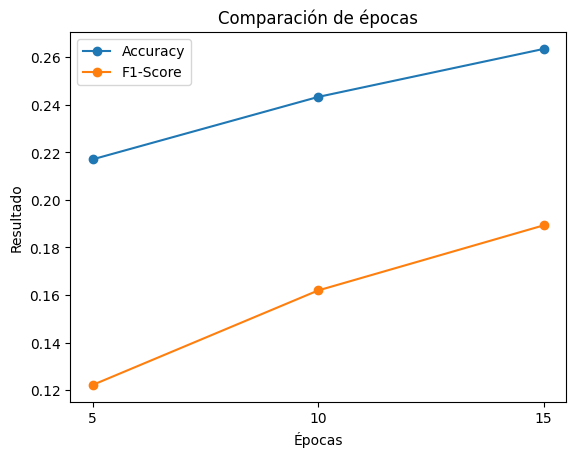

Mejor cantidad de épocas: 15
Accuracy: 0.2635
F1-Score: 0.1893
Loss: 4.3568

Interpretación: La configuración de 15 épocas obtuvo el mayor F1-Score de validación.


In [25]:
resultados_epocas = []

keras.backend.clear_session()
keras.utils.set_random_seed(42)

modelo_epocas, _, _ = crear_modelo_recurrente(
    arquitectura_seleccionada,
    datos_es_en["vocab_origen"],
    datos_es_en["vocab_destino"],
    embedding_dim=64,
    unidades=128,
    learning_rate=0.001
)

epocas_anteriores = 0

for epocas in [5, 10, 15]:

    print(f"\nEntrenando hasta {epocas} épocas")

    modelo_epocas.fit(
        [x_train_exp, dec_train_exp],
        y_train_exp,
        sample_weight=w_train_exp,
        initial_epoch=epocas_anteriores,
        epochs=epocas,
        batch_size=32,
        verbose=1
    )

    resultado = evaluar_modelo(
        modelo_epocas,
        datos_val_exp
    )

    resultados_epocas.append({
        "Épocas": epocas,
        **resultado
    })

    epocas_anteriores = epocas


tabla_epocas = pd.DataFrame(resultados_epocas)

display(tabla_epocas)


# Gráfico
plt.plot(
    tabla_epocas["Épocas"],
    tabla_epocas["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    tabla_epocas["Épocas"],
    tabla_epocas["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Épocas")
plt.ylabel("Resultado")
plt.title("Comparación de épocas")
plt.xticks([5, 10, 15])
plt.legend()
plt.show()


# Mejor resultado
mejor_epocas = tabla_epocas.loc[
    tabla_epocas["F1-Score"].idxmax()
]

EPOCAS_FINAL = int(mejor_epocas["Épocas"])

print("Mejor cantidad de épocas:", EPOCAS_FINAL)
print("Accuracy:", round(mejor_epocas["Accuracy"], 4))
print("F1-Score:", round(mejor_epocas["F1-Score"], 4))
print("Loss:", round(mejor_epocas["Loss"], 4))

print(
    f"\nInterpretación: La configuración de "
    f"{EPOCAS_FINAL} épocas obtuvo el mayor "
    f"F1-Score de validación."
)

La configuración de 15 épocas obtuvo el mayor F1-Score, alcanzando un valor de 0,1893 y un Accuracy de 0,2635.

Por esta razón se seleccionan 15 épocas para el entrenamiento final.

* **Experimento 2: Learning Rate**

El Learning Rate determina el tamaño de los cambios realizados por el optimizador durante el entrenamiento.

Se comparan tres valores utilizando 5 épocas y un Batch Size de 32, manteniendo las mismas condiciones para cada alternativa.


Probando Learning Rate: 0.0005
Epoch 1/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 32s 284ms/step - accuracy: 0.1297 - loss: 5.8727
Epoch 2/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 284ms/step - accuracy: 0.1583 - loss: 4.9699
Epoch 3/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 283ms/step - accuracy: 0.1677 - loss: 4.8369
Epoch 4/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 282ms/step - accuracy: 0.1800 - loss: 4.7282
Epoch 5/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 279ms/step - accuracy: 0.1847 - loss: 4.5995

Probando Learning Rate: 0.001
Epoch 1/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 278ms/step - accuracy: 0.1427 - loss: 5.5729
Epoch 2/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 284ms/step - accuracy: 0.1642 - loss: 4.8897
Epoch 3/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 285ms/step - accuracy: 0.1823 - loss: 4.6885
Epoch 4/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 284ms/step - accuracy: 0.1961 - loss: 4.4551
Epoch 5/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 285ms/step - accuracy: 0.2142 - loss: 4.2724

Probando Learning Rate: 0.005
Epoch 1/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 30s 283ms

,Learning Rate,Loss,Accuracy,Precision,Recall,F1-Score
0,0.0005,4.733672,0.190092,0.052446,0.190092,0.081207
1,0.0010,4.530153,0.217064,0.086488,0.217064,0.122224
2,0.0050,4.601831,0.211193,0.109193,0.211193,0.129430


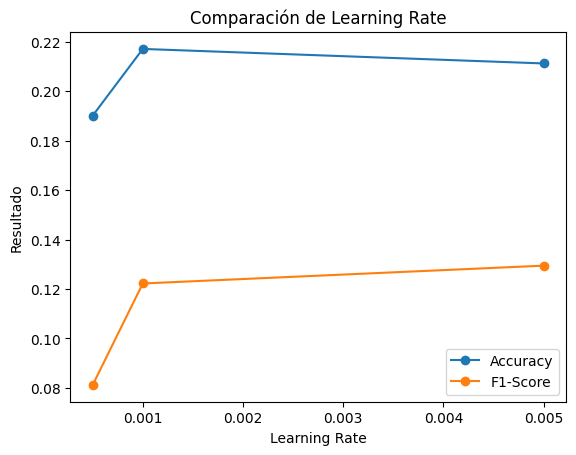

Learning Rate con mayor F1-Score: 0.005
Accuracy: 0.2112
F1-Score: 0.1294
Loss: 4.6018

Interpretación: El Learning Rate de 0.005 obtuvo el mayor F1-Score de validación.


In [26]:
resultados_lr = []

for lr in [0.0005, 0.001, 0.005]:

    print(f"\nProbando Learning Rate: {lr}")

    resultado = probar_configuracion(
        epocas=5,
        batch=32,
        learning_rate=lr
    )

    resultados_lr.append({
        "Learning Rate": lr,
        **resultado
    })


tabla_lr = pd.DataFrame(
    resultados_lr
)

display(tabla_lr)


# Gráfico
plt.plot(
    tabla_lr["Learning Rate"],
    tabla_lr["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    tabla_lr["Learning Rate"],
    tabla_lr["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Learning Rate")
plt.ylabel("Resultado")
plt.title("Comparación de Learning Rate")
plt.legend()
plt.show()


# Mejor resultado
mejor_lr = tabla_lr.loc[
    tabla_lr["F1-Score"].idxmax()
]

LR_FINAL = float(
    mejor_lr["Learning Rate"]
)

print("Learning Rate con mayor F1-Score:", LR_FINAL)
print("Accuracy:", round(mejor_lr["Accuracy"], 4))
print("F1-Score:", round(mejor_lr["F1-Score"], 4))
print("Loss:", round(mejor_lr["Loss"], 4))

print(
    f"\nInterpretación: El Learning Rate de "
    f"{LR_FINAL} obtuvo el mayor F1-Score "
    f"de validación."
)

El Learning Rate de 0,005 obtuvo el mayor F1-Score entre las configuraciones evaluadas, alcanzando un valor de 0,1294.

Por esta razón se selecciona este valor para los siguientes entrenamientos.

* **Experimento 3: Batch Size**

El Batch Size indica cuántas oraciones procesa el modelo antes de actualizar sus pesos.

Se comparan tres tamaños de lote utilizando 5 épocas y el Learning Rate de 0,005 seleccionado anteriormente.


Probando Batch Size: 16
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 33s 154ms/step - accuracy: 0.1637 - loss: 5.3011
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 29s 154ms/step - accuracy: 0.2019 - loss: 4.5455
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 45s 238ms/step - accuracy: 0.2181 - loss: 4.2055
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 67s 156ms/step - accuracy: 0.2285 - loss: 3.9325
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 41s 155ms/step - accuracy: 0.2349 - loss: 3.6951

Probando Batch Size: 32
Epoch 1/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 277ms/step - accuracy: 0.1557 - loss: 5.4740
Epoch 2/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 284ms/step - accuracy: 0.1745 - loss: 4.9574
Epoch 3/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 284ms/step - accuracy: 0.2015 - loss: 4.6146
Epoch 4/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 27s 285ms/step - accuracy: 0.2277 - loss: 4.3192
Epoch 5/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 27s 285ms/step - accuracy: 0.2421 - loss: 4.0771

Probando Batch Size: 64
Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 28s 518ms/step - a

,Batch Size,Loss,Accuracy,Precision,Recall,F1-Score
0,16,4.824824,0.209358,0.117667,0.209358,0.140229
1,32,4.601831,0.211193,0.109193,0.211193,0.129430
2,64,4.902781,0.194495,0.069693,0.194495,0.094891


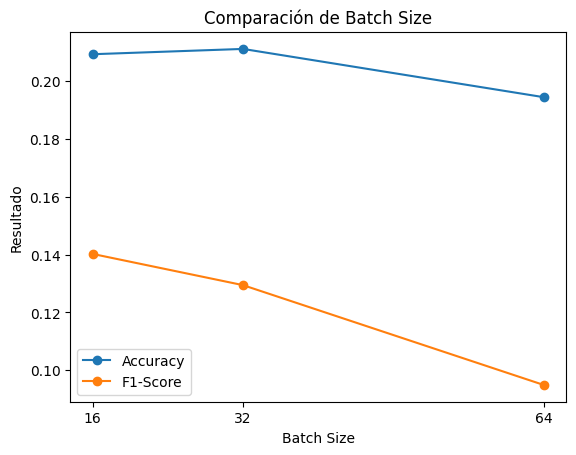

Batch Size con mayor F1-Score: 16
Accuracy: 0.2094
F1-Score: 0.1402
Loss: 4.8248

Interpretación: El Batch Size de 16 obtuvo el mayor F1-Score de validación.


In [27]:
resultados_batch = []

for batch in [16, 32, 64]:

    print(f"\nProbando Batch Size: {batch}")

    resultado = probar_configuracion(
        epocas=5,
        batch=batch,
        learning_rate=LR_FINAL
    )

    resultados_batch.append({
        "Batch Size": batch,
        **resultado
    })


tabla_batch = pd.DataFrame(
    resultados_batch
)

display(tabla_batch)


# Gráfico
plt.plot(
    tabla_batch["Batch Size"],
    tabla_batch["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    tabla_batch["Batch Size"],
    tabla_batch["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Batch Size")
plt.ylabel("Resultado")
plt.title("Comparación de Batch Size")
plt.xticks([16, 32, 64])
plt.legend()
plt.show()


# Mejor resultado
mejor_batch = tabla_batch.loc[
    tabla_batch["F1-Score"].idxmax()
]

BATCH_FINAL = int(
    mejor_batch["Batch Size"]
)

print("Batch Size con mayor F1-Score:", BATCH_FINAL)
print("Accuracy:", round(mejor_batch["Accuracy"], 4))
print("F1-Score:", round(mejor_batch["F1-Score"], 4))
print("Loss:", round(mejor_batch["Loss"], 4))

print(
    f"\nInterpretación: El Batch Size de "
    f"{BATCH_FINAL} obtuvo el mayor F1-Score "
    f"de validación."
)

El Batch Size de 16 obtuvo el mayor F1-Score entre las configuraciones evaluadas, alcanzando un valor de 0,1402.

Por esta razón se selecciona este tamaño de lote para los entrenamientos finales.

# 8. Selección de configuración final

In [28]:
tabla_configuracion_final = pd.DataFrame({

    "Parámetro": [
        "Arquitectura",
        "Encoder",
        "Decoder",
        "Embedding",
        "Unidades recurrentes",
        "Épocas",
        "Batch Size",
        "Learning Rate",
        "Optimizador",
        "Función de pérdida"
    ],

    "Valor seleccionado": [
        arquitectura_seleccionada,
        "1 capa",
        "1 capa",
        64,
        128,
        EPOCAS_FINAL,
        BATCH_FINAL,
        LR_FINAL,
        "Adam",
        "Sparse Categorical Crossentropy"
    ]

})

tabla_configuracion_final

,Parámetro,Valor seleccionado
0,Arquitectura,RNN
1,Encoder,1 capa
2,Decoder,1 capa
3,Embedding,64
4,Unidades recurrentes,128
5,Épocas,15
6,Batch Size,16
7,Learning Rate,0.005
8,Optimizador,Adam
9,Función de pérdida,Sparse Categorical Crossentropy


# 9. Entrenamiento del modelo final

* **Modelo final Español → Inglés**

El modelo se vuelve a entrenar desde cero utilizando la arquitectura y los hiperparámetros seleccionados mediante los experimentos.

In [29]:
keras.backend.clear_session()
keras.utils.set_random_seed(42)

modelo_final_es_en, encoder_es_en, decoder_es_en = (
    crear_modelo_recurrente(
        arquitectura_seleccionada,
        datos_es_en["vocab_origen"],
        datos_es_en["vocab_destino"],
        embedding_dim=64,
        unidades=128,
        learning_rate=LR_FINAL
    )
)

history_final_es_en = modelo_final_es_en.fit(

    [x_train, dec_train],

    y_train,

    sample_weight=w_train,

    validation_data=(
        [x_val, dec_val],
        y_val,
        w_val
    ),

    epochs=EPOCAS_FINAL,

    batch_size=BATCH_FINAL,

    verbose=1
)

Epoch 1/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 80s 174ms/step - accuracy: 0.1886 - loss: 4.9127 - val_accuracy: 0.2140 - val_loss: 4.5003
Epoch 2/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 79s 167ms/step - accuracy: 0.2224 - loss: 4.2333 - val_accuracy: 0.2286 - val_loss: 4.4618
Epoch 3/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 74s 169ms/step - accuracy: 0.2462 - loss: 3.9003 - val_accuracy: 0.2392 - val_loss: 4.4847
Epoch 4/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 82s 170ms/step - accuracy: 0.2622 - loss: 3.6485 - val_accuracy: 0.2405 - val_loss: 4.5370
Epoch 5/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 86s 180ms/step - accuracy: 0.2681 - loss: 3.4674 - val_accuracy: 0.2387 - val_loss: 4.6090
Epoch 6/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 77s 169ms/step - accuracy: 0.2803 - loss: 3.2988 - val_accuracy: 0.2390 - val_loss: 4.6900
Epoch 7/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 73s 167ms/step - accuracy: 0.2972 - loss: 3.1483 - val_accuracy: 0.2370 - val_loss: 4.7442
Epoch 8/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 73s 167ms/step - accuracy: 0.3078 - loss: 3

* **Accuracy del modelo final**

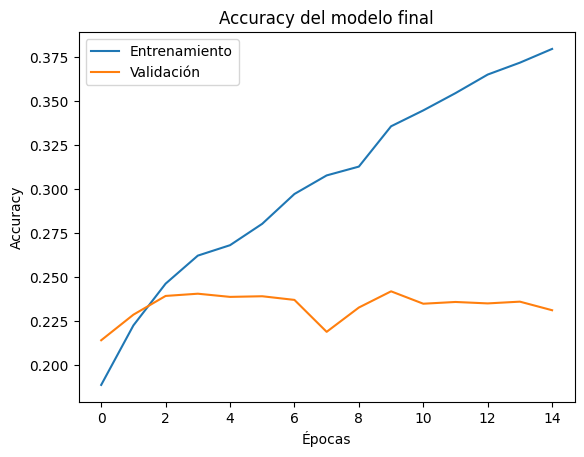

In [30]:
plt.plot(
    history_final_es_en.history[
        "accuracy"
    ],
    label="Entrenamiento"
)

plt.plot(
    history_final_es_en.history[
        "val_accuracy"
    ],
    label="Validación"
)

plt.xlabel(
    "Épocas"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Accuracy del modelo final"
)

plt.legend()

plt.show()

* **Pérdida del modelo final**

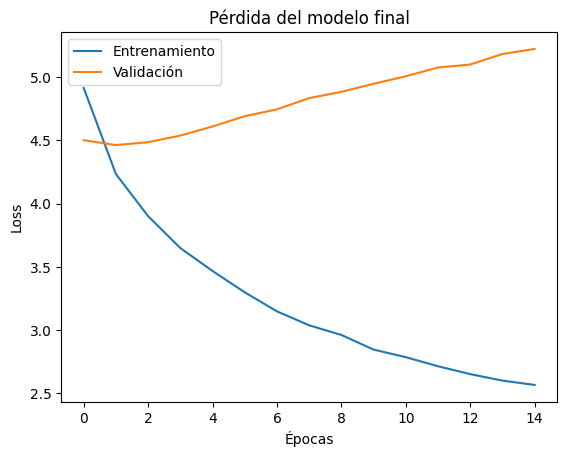

In [31]:
plt.plot(
    history_final_es_en.history[
        "loss"
    ],
    label="Entrenamiento"
)

plt.plot(
    history_final_es_en.history[
        "val_loss"
    ],
    label="Validación"
)

plt.xlabel(
    "Épocas"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Pérdida del modelo final"
)

plt.legend()

plt.show()

* **Modelo final Inglés → Español**

Para mantener la misma configuración en ambos sentidos de traducción se utiliza la arquitectura y los hiperparámetros seleccionados anteriormente.

In [33]:
x_train_en, dec_train_en, y_train_en, w_train_en = (
    datos_en_es["train"]
)

x_val_en, dec_val_en, y_val_en, w_val_en = (
    datos_en_es["val"]
)

keras.utils.set_random_seed(42)

modelo_final_en_es, encoder_en_es, decoder_en_es = (
    crear_modelo_recurrente(
        arquitectura_seleccionada,
        datos_en_es["vocab_origen"],
        datos_en_es["vocab_destino"],
        embedding_dim=64,
        unidades=128,
        learning_rate=LR_FINAL
    )
)

history_final_en_es = modelo_final_en_es.fit(
    [x_train_en, dec_train_en],
    y_train_en,
    sample_weight=w_train_en,
    validation_data=(
        [x_val_en, dec_val_en],
        y_val_en,
        w_val_en
    ),
    epochs=EPOCAS_FINAL,
    batch_size=BATCH_FINAL,
    verbose=1
)

Epoch 1/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 110s 242ms/step - accuracy: 0.1739 - loss: 5.3724 - val_accuracy: 0.1913 - val_loss: 5.0229
Epoch 2/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 102s 232ms/step - accuracy: 0.2030 - loss: 4.6145 - val_accuracy: 0.1869 - val_loss: 5.0688
Epoch 3/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 140s 228ms/step - accuracy: 0.2216 - loss: 4.2451 - val_accuracy: 0.1950 - val_loss: 5.1022
Epoch 4/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 102s 233ms/step - accuracy: 0.2323 - loss: 3.9849 - val_accuracy: 0.2066 - val_loss: 5.2007
Epoch 5/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 141s 231ms/step - accuracy: 0.2496 - loss: 3.7645 - val_accuracy: 0.2035 - val_loss: 5.2878
Epoch 6/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 146s 241ms/step - accuracy: 0.2574 - loss: 3.5995 - val_accuracy: 0.2017 - val_loss: 5.3636
Epoch 7/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 136s 228ms/step - accuracy: 0.2727 - loss: 3.4118 - val_accuracy: 0.2010 - val_loss: 5.4506
Epoch 8/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 105s 239ms/step - accuracy: 0.2847 -

# 10. Evaluación final

* **Métricas del conjunto de prueba**

Una vez seleccionada la configuración final se utilizan los datos de prueba, que no participaron en la selección de la arquitectura ni de los hiperparámetros.

In [38]:
metricas_final_es_en = evaluar_modelo(

    modelo_final_es_en,

    datos_es_en[
        "test"
    ]
)


metricas_final_en_es = evaluar_modelo(

    modelo_final_en_es,

    datos_en_es[
        "test"
    ]
)


tabla_metricas_final = pd.DataFrame([

    {
        "Dirección":
            "Español → Inglés",

        **metricas_final_es_en
    },

    {
        "Dirección":
            "Inglés → Español",

        **metricas_final_en_es
    }

])


tabla_metricas_final

,Dirección,Loss,Accuracy,Precision,Recall,F1-Score
0,Español → Inglés,5.134479,0.233533,0.200594,0.233533,0.201163
1,Inglés → Español,5.993955,0.209736,0.175231,0.209736,0.179992


# 11. Pruebas de traducción

* **Función para traducir**

La traducción comienza utilizando `startseq`.

El Decoder predice una palabra, esa palabra vuelve a utilizarse como entrada y el proceso continúa hasta predecir `endseq` o alcanzar el largo máximo permitido.

Para comprobar el funcionamiento del modelo se seleccionan cinco oraciones completas del conjunto de prueba.

Estas oraciones no fueron utilizadas durante el entrenamiento del modelo.

Para cada ejemplo se muestra:

- **Entrada:** oración original que recibe el modelo.
- **Esperado:** traducción correcta disponible en el dataset.
- **Obtenido:** traducción generada por la red neuronal.

Se utiliza una semilla fija para seleccionar siempre los mismos ejemplos y mantener los resultados reproducibles.

In [34]:
def traducir(
    frase,
    datos,
    arquitectura,
    modelo_encoder,
    modelo_decoder
):

    frase = limpiar_texto(frase)

    secuencia = datos[
        "tokenizer_origen"
    ].texts_to_sequences([frase])

    secuencia = pad_sequences(
        secuencia,
        maxlen=datos["max_origen"],
        padding="post",
        truncating="post"
    )

    tokenizer = datos["tokenizer_destino"]

    inicio = tokenizer.word_index["startseq"]
    fin = tokenizer.word_index["endseq"]

    token_actual = np.array(
        [[inicio]],
        dtype=np.int32
    )

    palabras = []

    # Obtener estados del Encoder
    estados = modelo_encoder(
        secuencia,
        training=False
    )

    if arquitectura == "RNN":
        estados = [estados]
    else:
        estados = list(estados)

    # Generar traducción
    for _ in range(datos["max_destino"] - 1):

        salidas = modelo_decoder(
            [
                tf.convert_to_tensor(token_actual),
                *estados
            ],
            training=False
        )

        probabilidades = salidas[0]
        estados = list(salidas[1:])

        siguiente = int(
            tf.argmax(
                probabilidades[0, -1]
            ).numpy()
        )

        if siguiente in [0, fin]:
            break

        palabra = tokenizer.index_word.get(
            siguiente,
            "oov"
        )

        palabras.append(palabra)

        token_actual = np.array(
            [[siguiente]],
            dtype=np.int32
        )

    return " ".join(palabras)

* **Pruebas Español → Inglés**

In [35]:
muestra_es_en = df_test.sample(
    n=5,
    random_state=42
)


for _, fila in muestra_es_en.iterrows():

    traduccion = traducir(

        fila[
            "Español"
        ],

        datos_es_en,

        arquitectura_seleccionada,

        encoder_es_en,

        decoder_es_en
    )


    print(
        "Entrada:",
        fila["Español"]
    )

    print(
        "Esperado:",
        fila["Inglés"]
    )

    print(
        "Obtenido:",
        traduccion
    )

    print()

Entrada: La mujer está desnuda.
Esperado: The woman is naked.
Obtenido: the forecast for me

Entrada: Tom sangra otra vez.
Esperado: Tom is bleeding again.
Obtenido: tom lives on the ocean of people

Entrada: Mi novia es muy hermosa.
Esperado: My girlfriend is very beautiful.
Obtenido: i have a lot of people

Entrada: No llevó mucho tiempo.
Esperado: That didn't take long.
Obtenido: the forecast for me

Entrada: Venga, prueba otra vez.
Esperado: OK, try again.
Obtenido: the forecast for me



* **Pruebas Inglés → Español**

In [37]:
muestra_en_es = df_test.sample(
    n=5,
    random_state=42
)


for _, fila in muestra_en_es.iterrows():

    traduccion = traducir(

        fila[
            "Inglés"
        ],

        datos_en_es,

        arquitectura_seleccionada,

        encoder_en_es,

        decoder_en_es
    )


    print(
        "Entrada:",
        fila["Inglés"]
    )

    print(
        "Esperado:",
        fila["Español"]
    )

    print(
        "Obtenido:",
        traduccion
    )

    print()

Entrada: The woman is naked.
Esperado: La mujer está desnuda.
Obtenido: esta noche terminaré con mi tío

Entrada: Tom is bleeding again.
Esperado: Tom sangra otra vez.
Obtenido: tom no fue el único que no hizo nada

Entrada: My girlfriend is very beautiful.
Esperado: Mi novia es muy hermosa.
Obtenido: él no es maestro sino médico

Entrada: That didn't take long.
Esperado: No llevó mucho tiempo.
Obtenido: acudieron cuarenta personas

Entrada: OK, try again.
Esperado: Venga, prueba otra vez.
Obtenido: esta noche terminaré con mi tío



# 12. Análisis de las traducciones

Las traducciones obtenidas muestran que el modelo logra generar palabras y estructuras de ambos idiomas.

Sin embargo, en la mayoría de los ejemplos no se conserva el significado de la oración original.

También se observa la repetición de algunas traducciones para diferentes oraciones de entrada.

Estos resultados evidencian las limitaciones del modelo para comprender el contexto y generalizar sobre oraciones que no participaron en el entrenamiento.

# 13. Posibles mejoras

El modelo podría mejorarse utilizando una mayor cantidad de datos, incorporando mecanismos de atención o aumentando la capacidad de la arquitectura.

También sería conveniente utilizar Early Stopping para detener el entrenamiento cuando la pérdida de validación deje de mejorar y reducir el sobreajuste observado.

# 14. Conclusión

Se desarrolló un modelo recurrente Encoder-Decoder para traducción Español-Inglés e Inglés-Español.

La comparación inicial mostró un mejor rendimiento de RNN frente a LSTM. Posteriormente se evaluaron distintas cantidades de épocas, Learning Rates y tamaños de Batch, seleccionando 15 épocas, Learning Rate de 0,005 y Batch Size de 16.

Aunque el modelo logró generar secuencias de palabras en ambos idiomas, las traducciones presentan errores semánticos y dificultades para conservar el significado original.

Las curvas de entrenamiento también evidencian la presencia de sobreajuste, lo que indica que existen oportunidades de mejora en la capacidad de generalización del modelo.